In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

## Import $Q$-vectors, Thrust 

In [2]:
labels = {'Z': r'$Z\to q\bar q$', 
          'Z1': r'$Z\to q\bar q$, 1 splitting', 
        #   'Z2': r'$Z\to q\bar q$, 2 splittings',
        #   'Z3': r'$Z\to q\bar q$, 3 splittings', 'Z4': r'$Z\to q\bar q$, 4 splittings',
          'Z1_500GeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 500$ GeV', 
          'Z1_1TeV': r'$Z\to q\bar q$, 1 splitting, $\sqrt{s} = 1$ TeV',
          'Z1_fix08': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$',
          'Z1_fix12': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$',
          'Z1_fix16': r'$Z\to q\bar q$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$',
          }

In [3]:
#########################################################
### Load features (computed in make_features.ipynb)
#########################################################

QVC_sets = {k: np.load(f'features/QVEC_nq2048_{k}.npy', mmap_mode='r') for k in labels if os.path.exists(f'features/QVEC_nq2048_{k}.npy')}
print('Qvc:', {k: v.shape for k, v in QVC_sets.items()}, '  missing:', [k for k in labels if k not in QVC_sets])

#########################################################
### Load targets (computed in Make_Features.ipynb)
#########################################################
thrusts = {k: np.load(f'features/TARGETS_{k}.npz')['thrust'] for k in labels if os.path.exists(f'features/TARGETS_{k}.npz')}
print('thrust:', {k: v.shape for k, v in thrusts.items()}, '  missing:', [k for k in labels if k not in thrusts])

Qvc: {'Z': (100000, 2048), 'Z1': (99387, 2048), 'Z1_500GeV': (100000, 2048), 'Z1_1TeV': (99999, 2048), 'Z1_fix08': (73394, 2048), 'Z1_fix12': (86070, 2048), 'Z1_fix16': (92872, 2048)}   missing: []
thrust: {'Z': (100000,), 'Z1': (99387,), 'Z1_500GeV': (100000,), 'Z1_1TeV': (99999,), 'Z1_fix08': (73394,), 'Z1_fix12': (86070,), 'Z1_fix16': (92872,)}   missing: []


## Regress $Q \rightarrow$ Thrust with KRR 

In [4]:
## train on QVC_sets --> regress to thrusts ... better on gpu 
λs = [1e-10]
Ps = np.unique(np.round(np.logspace(0, 3.5, 40)).astype(int))   
n_reps = lambda P: max(int(5000 / P), 50)
KRR_NTK_losses = {λ: {} for λ in λs}
for λ in λs: 
    for label in labels: 
        print(label)
        KRR_NTK_losses[λ][label] = run_regression_sweep(QVC_sets[label], thrusts[label],  Ps, λ=λ, n_repeats=n_reps, test_size=0.2, 
                                        w_true=None, filter_zero_var=True, center=True, scale=True, kern="NTK", depth=4)


Z
(80000, 1967) (20000, 1967) 51.2 GB per train Gram
       1  |  0.003784
       2  |  0.003286
       3  |  0.002785
       4  |  0.002412
       5  |  0.002146
       6  |  0.001805
       8  |  0.001447
      10  |  0.001176
      12  |  0.000993
      15  |  0.000774
      18  |  0.000801
      22  |  0.000630
      27  |  0.000554
      34  |  0.000429
      41  |  0.000409
      51  |  0.000362
      62  |  0.000334
      77  |  0.000314
      94  |  0.000269
     116  |  0.000251
     143  |  0.000225
     175  |  0.000212
     215  |  0.000198
     265  |  0.000185
     326  |  0.000167
     400  |  0.000158
     492  |  0.000149
     605  |  0.000139
     744  |  0.000127
     915  |  0.000120
    1125  |  0.000113
    1384  |  0.000103
    1701  |  0.000096
    2092  |  0.000090
    2572  |  0.000085
    3162  |  0.000079
Z1
(79509, 1365) (19878, 1365) 50.6 GB per train Gram
       1  |  0.002756
       2  |  0.002387
       3  |  0.002100
       4  |  0.001773
       5  |  

In [5]:
### Save the Losses
depth = 4
for λ in λs:
    for label, (L, S) in KRR_NTK_losses[λ].items():
        np.savez(f'losses/KRR_NTK_d{depth}_lam{λ:g}_{label}.npz', Ps=Ps, loss=L, std=S, reps=[n_reps(P) for P in Ps])

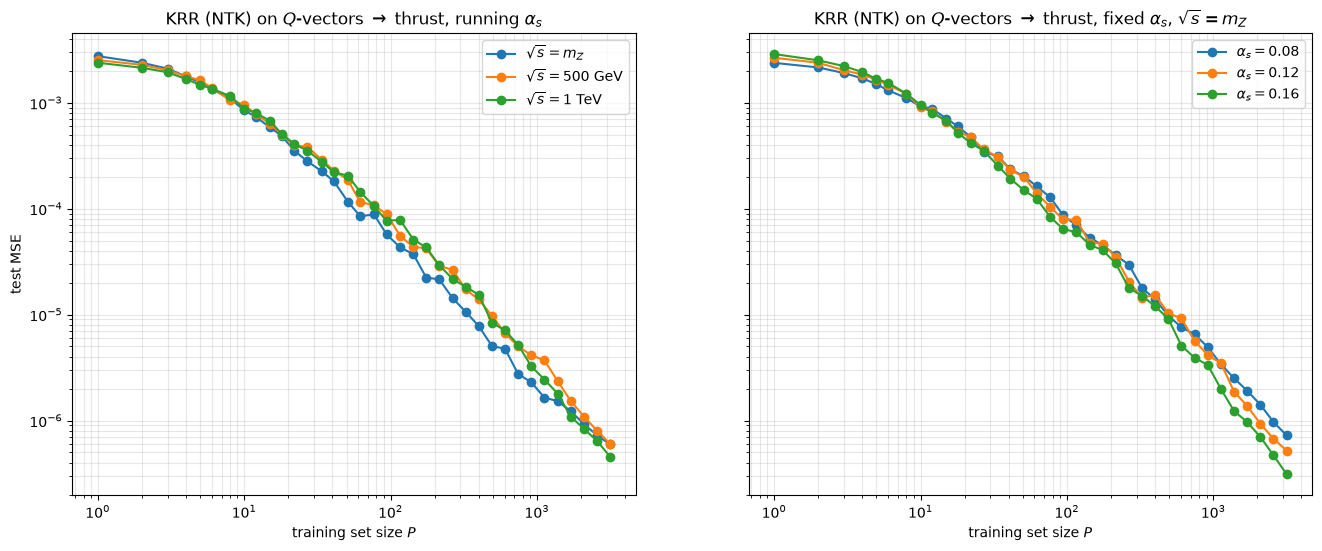

In [6]:
λ = 1e-10
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

ax1.loglog(Ps, KRR_NTK_losses[λ]['Z1'][0], 'o-', color='C0', label=r'$\sqrt{s} = m_Z$')
ax1.loglog(Ps, KRR_NTK_losses[λ]['Z1_500GeV'][0], 'o-', color='C1', label=r'$\sqrt{s} = 500$ GeV')
ax1.loglog(Ps, KRR_NTK_losses[λ]['Z1_1TeV'][0], 'o-', color='C2', label=r'$\sqrt{s} = 1$ TeV')
ax1.set_title(r'KRR (NTK) on $Q$-vectors $\to$ thrust, running $\alpha_s$'); ax1.set_xlabel('training set size $P$'); ax1.set_ylabel('test MSE')
ax1.legend(); ax1.grid(True, which='both', alpha=0.3)

ax2.loglog(Ps, KRR_NTK_losses[λ]['Z1_fix08'][0], 'o-', color='C0', label=r'$\alpha_s = 0.08$')
ax2.loglog(Ps, KRR_NTK_losses[λ]['Z1_fix12'][0], 'o-', color='C1', label=r'$\alpha_s = 0.12$')
ax2.loglog(Ps, KRR_NTK_losses[λ]['Z1_fix16'][0], 'o-', color='C2', label=r'$\alpha_s = 0.16$')
ax2.set_title(r'KRR (NTK) on $Q$-vectors $\to$ thrust, fixed $\alpha_s$, $\sqrt{s} = m_Z$'); ax2.set_xlabel('training set size $P$')
ax2.legend(); ax2.grid(True, which='both', alpha=0.3)

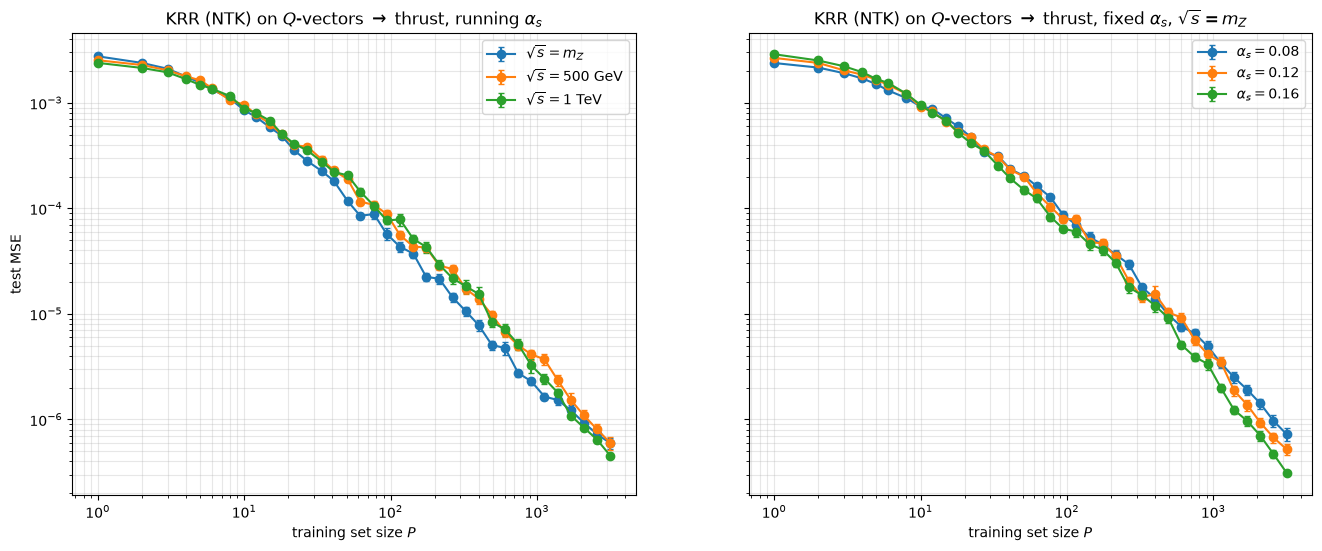

In [7]:
λ = 1e-10
reps = np.array([n_reps(P) for P in Ps])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

L, S = KRR_NTK_losses[λ]['Z1'];        ax1.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C0', capsize=2, label=r'$\sqrt{s} = m_Z$')
L, S = KRR_NTK_losses[λ]['Z1_500GeV']; ax1.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C1', capsize=2, label=r'$\sqrt{s} = 500$ GeV')
L, S = KRR_NTK_losses[λ]['Z1_1TeV'];   ax1.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C2', capsize=2, label=r'$\sqrt{s} = 1$ TeV')
ax1.set_title(r'KRR (NTK) on $Q$-vectors $\to$ thrust, running $\alpha_s$'); ax1.set_xlabel('training set size $P$'); ax1.set_ylabel('test MSE')
ax1.set_xscale('log'); ax1.set_yscale('log'); ax1.legend(); ax1.grid(True, which='both', alpha=0.3)

L, S = KRR_NTK_losses[λ]['Z1_fix08'];  ax2.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C0', capsize=2, label=r'$\alpha_s = 0.08$')
L, S = KRR_NTK_losses[λ]['Z1_fix12'];  ax2.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C1', capsize=2, label=r'$\alpha_s = 0.12$')
L, S = KRR_NTK_losses[λ]['Z1_fix16'];  ax2.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C2', capsize=2, label=r'$\alpha_s = 0.16$')
ax2.set_title(r'KRR (NTK) on $Q$-vectors $\to$ thrust, fixed $\alpha_s$, $\sqrt{s} = m_Z$'); ax2.set_xlabel('training set size $P$')
ax2.set_xscale('log'); ax2.legend(); ax2.grid(True, which='both', alpha=0.3)

In [8]:
def local_slope(lam, k=None, kmax=1000, w=1):
    """alpha(k) = -dlog(lam)/dlog(k) from a linear fit over |log k' - log k| <= w."""
    k = np.arange(1, len(lam) + 1) if k is None else np.asarray(k); m = (lam > 0) & (k <= kmax)
    lk, ll = np.log(k[m]), np.log(lam[m])
    a = [-np.polyfit(lk[np.abs(lk - x) <= w], ll[np.abs(lk - x) <= w], 1)[0] if (np.abs(lk - x) <= w).sum() > 2 else np.nan for x in lk]
    return k[m], np.array(a)

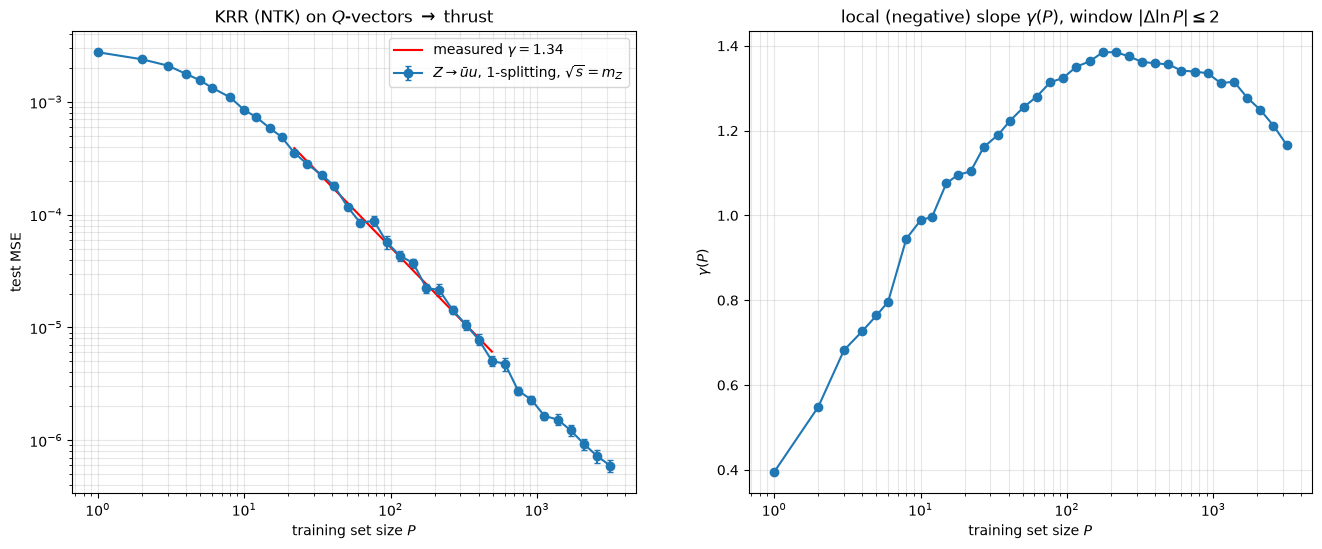

In [9]:
key = 'Z1' 
λ, w = 1e-10, 2
reps = np.array([n_reps(P) for P in Ps])
L, S = KRR_NTK_losses[λ][key]
P, local_gamma = local_slope(L, k=Ps, kmax=np.inf, w=w)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C0', capsize=2, label=r'$Z\rightarrow \bar{u}u$, 1-splitting, $\sqrt{s} = m_Z$')
# fit 
lo, hi = 2e1, 5e2
mask = (Ps > lo) & (Ps < hi)
fit = np.polyfit(np.log(Ps[mask]), np.log(KRR_NTK_losses[λ][key][0][mask]), 1)
gamma = -fit[0]
ax1.loglog(Ps[mask], np.exp(np.polyval(fit, np.log(Ps[mask]))), 'r-', label=rf'measured $\gamma = {gamma:.2f}$')
# 
ax1.set_title(rf'KRR (NTK) on $Q$-vectors $\to$ thrust'); 
ax1.set_xlabel('training set size $P$'); 
ax1.set_ylabel('test MSE')
ax1.set_xscale('log'); ax1.set_yscale('log'); 
ax1.grid(True, which='both', alpha=0.3); ax1.legend()

ax2.plot(P, local_gamma, 'o-', color='C0')
ax2.set_title(rf'local (negative) slope $\gamma(P)$, window $|\Delta \ln P| \leq {w}$'); 
ax2.set_xlabel('training set size $P$'); 
ax2.set_ylabel(r'$\gamma(P)$')
ax2.set_xscale('log'); ax2.grid(True, which='both', alpha=0.3)

## Regress $Q \rightarrow$ Thrust with NN